1. Configuración e importación de librerías

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from IPython.display import display

CONTAMINANTES = ['pm10', 'pm2_5', 'carbon_monoxide', 'nitrogen_dioxide', 'sulphur_dioxide', 'ozone']
OBJETIVOS = ['pm2_5', 'pm10']

In [2]:
from google.colab import drive
import os

# Montar Google Drive
if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')

# Cargar el dataset
df = pd.read_csv("/content/drive/MyDrive/air_quality_historical.csv")
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)
print('Dimensiones del dataset original:', df.shape)

Mounted at /content/drive
Dimensiones del dataset original: (1298, 12)


3. Comprensión inicial de los datos

In [3]:
display(df.head(10))

,date,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,aerosol_optical_depth,dust,uv_index,us_aqi,european_aqi
0,2022-08-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2022-08-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2022-08-03,20.820000,14.620000,309.600000,21.160000,1.360000,36.600000,0.232000,0.00,0.000000,NaN,NaN
3,2022-08-04,19.175000,13.470833,285.375000,12.387500,0.779167,52.458333,0.145000,0.00,1.552083,51.200000,25.000000
4,2022-08-05,23.483333,16.433333,400.708333,15.445833,0.979167,48.625000,0.200833,0.00,1.933333,57.833333,31.875000
5,2022-08-06,21.220833,14.850000,339.791667,16.375000,1.533333,48.208333,0.174583,0.00,1.560417,55.958333,30.000000
6,2022-08-07,20.787500,14.545833,395.625000,16.562500,1.229167,49.875000,0.120000,0.00,2.460417,57.833333,31.791667
7,2022-08-08,18.691667,13.066667,346.416667,19.250000,1.058333,61.375000,0.102917,0.00,2.579167,52.125000,30.125000
8,2022-08-09,17.591667,12.279167,362.708333,18.345833,1.279167,58.708333,0.111667,0.25,2.216667,53.791667,30.208333
9,2022-08-10,15.329167,10.729167,267.250000,12.929167,1.066667,56.791667,0.114583,0.00,2.210417,44.375000,24.416667


In [4]:
df.columns

Index(['date', 'pm10', 'pm2_5', 'carbon_monoxide', 'nitrogen_dioxide',
       'sulphur_dioxide', 'ozone', 'aerosol_optical_depth', 'dust', 'uv_index',
       'us_aqi', 'european_aqi'],
      dtype='object')

In [5]:
# Valores nulos por columna y filas que los contienen
print('Valores nulos por columna:')
print(df.isnull().sum())
filas_nulas = df[df.isnull().any(axis=1)]
print('\nFilas con algún valor nulo:')
display(filas_nulas[['date']].assign(n_nulos=filas_nulas.isnull().sum(axis=1)))

Valores nulos por columna:
date                     0
pm10                     2
pm2_5                    2
carbon_monoxide          2
nitrogen_dioxide         2
sulphur_dioxide          2
ozone                    2
aerosol_optical_depth    2
dust                     2
uv_index                 2
us_aqi                   3
european_aqi             3
dtype: int64

Filas con algún valor nulo:


,date,n_nulos
0,2022-08-01,11
1,2022-08-02,11
2,2022-08-03,2


In [6]:
print('\nTipos de datos:')
df.dtypes


Tipos de datos:


,0
date,datetime64[ns]
pm10,float64
pm2_5,float64
carbon_monoxide,float64
nitrogen_dioxide,float64
sulphur_dioxide,float64
ozone,float64
aerosol_optical_depth,float64
dust,float64
uv_index,float64


In [7]:
df.describe()

,date,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,aerosol_optical_depth,dust,uv_index,us_aqi,european_aqi
count,1298,1296.000000,1296.000000,1296.000000,1296.000000,1296.000000,1296.000000,1296.000000,1296.000000,1296.000000,1295.000000,1295.000000
mean,2024-05-10 12:00:00,17.330526,13.641467,485.111092,14.302036,4.227017,55.211529,0.255428,0.159176,1.810079,51.804208,30.788932
min,2022-08-01 00:00:00,1.170833,0.812500,59.750000,0.000000,0.383333,25.500000,0.032917,0.000000,0.000000,13.375000,11.500000
25%,2023-06-21 06:00:00,13.436458,10.728125,327.864583,11.719792,2.984375,48.916667,0.182917,0.000000,1.395833,45.083333,26.104167
50%,2024-05-10 12:00:00,16.760417,13.420833,414.958333,13.995833,4.477083,55.666667,0.240000,0.000000,1.802083,52.750000,29.833333
75%,2025-03-30 18:00:00,20.648958,16.302083,607.114583,16.613542,5.395833,61.468750,0.305417,0.000000,2.216667,58.895833,34.666667
max,2026-02-18 00:00:00,44.804167,32.741667,1461.666667,27.341667,19.266667,86.666667,0.913750,12.500000,3.206250,90.250000,64.666667
std,NaN,5.539013,4.092616,209.902852,3.645865,2.033058,9.787966,0.104629,0.678755,0.543463,10.864758,7.515072


4. Verificacion de integridad

In [8]:
num_cols = df.select_dtypes(include=np.number).columns

# 4.1 Duplicados, negativos y continuidad del calendario
rango_completo = pd.date_range(df['date'].min(), df['date'].max(), freq='D')
print('Registros duplicados:', df.duplicated().sum())
print('Fechas duplicadas:', df['date'].duplicated().sum())
print('Días faltantes en el calendario:', len(rango_completo.difference(df['date'])))
print('Valores negativos totales:', int((df[num_cols] < 0).sum().sum()))

# 4.2 Valores exactamente iguales a cero (físicamente sospechosos en promedios diarios)
ceros = (df[num_cols] == 0).sum()
print('\nValores iguales a cero por variable:')
print(ceros[ceros > 0])
for col in ['nitrogen_dioxide', 'uv_index']:
    print(f"  Fechas con {col} = 0:", df.loc[df[col] == 0, 'date'].dt.strftime('%Y-%m-%d').tolist())

# 4.3 Coherencia física: PM2.5 no puede superar a PM10 (PM2.5 es una fracción del PM10)
ratio = df['pm2_5'] / df['pm10']
print(f"\nRelación PM2.5/PM10 -> mínimo {ratio.min():.2f} | mediana {ratio.median():.2f} | máximo {ratio.max():.2f}")
print('Días con PM2.5 > PM10:', int((ratio > 1.0001).sum()))

Registros duplicados: 0
Fechas duplicadas: 0
Días faltantes en el calendario: 0
Valores negativos totales: 0

Valores iguales a cero por variable:
nitrogen_dioxide       1
dust                1075
uv_index               1
dtype: int64
  Fechas con nitrogen_dioxide = 0: ['2022-12-14']
  Fechas con uv_index = 0: ['2022-08-03']

Relación PM2.5/PM10 -> mínimo 0.58 | mediana 0.70 | máximo 1.00
Días con PM2.5 > PM10: 0


5. Limpieza de datos

In [9]:
df_cleaned = df.copy()
registro_intervenciones = []

# 5.1 Poda de borde: 2022-08-01 y 2022-08-02 no tienen ningún dato (11 de 11 variables nulas)
df_cleaned = df_cleaned.iloc[2:].reset_index(drop=True)
registro_intervenciones.append(('2022-08-01 y 2022-08-02', 'Todas', 'Eliminadas (sin datos)', 'Poda de borde'))

# 5.2 Índices AQI nulos en 2022-08-03: se completan con el valor del día siguiente (bfill).
#     Justificación: los AQI NO se usan como predictores (se excluyen para evitar fuga de información),
#     por lo que esta imputación solo afecta a las gráficas descriptivas.
for col in ['us_aqi', 'european_aqi']:
    fechas = df_cleaned.loc[df_cleaned[col].isnull(), 'date'].dt.strftime('%Y-%m-%d').tolist()
    df_cleaned[col] = df_cleaned[col].bfill()
    registro_intervenciones.append((str(fechas), col, 'Nulo', 'Valor del día siguiente (bfill)'))

# 5.3 NO2 = 0 (dato inválido): se reemplaza por interpolación lineal entre el día anterior y el siguiente
mask_no2 = df_cleaned['nitrogen_dioxide'] == 0
fechas_no2 = df_cleaned.loc[mask_no2, 'date'].dt.strftime('%Y-%m-%d').tolist()
df_cleaned.loc[mask_no2, 'nitrogen_dioxide'] = np.nan
df_cleaned['nitrogen_dioxide'] = df_cleaned['nitrogen_dioxide'].interpolate(method='linear')
registro_intervenciones.append((str(fechas_no2), 'nitrogen_dioxide', '0 (inválido)', 'Interpolación lineal'))

# 5.4 UV = 0 en el primer día (registro incompleto): al estar en el borde no se puede interpolar,
#     se usa el valor del día siguiente
mask_uv = df_cleaned['uv_index'] == 0
fechas_uv = df_cleaned.loc[mask_uv, 'date'].dt.strftime('%Y-%m-%d').tolist()
df_cleaned.loc[mask_uv, 'uv_index'] = np.nan
df_cleaned['uv_index'] = df_cleaned['uv_index'].bfill()
registro_intervenciones.append((str(fechas_uv), 'uv_index', '0 (inválido)', 'Valor del día siguiente (bfill)'))

tabla_intervenciones = pd.DataFrame(registro_intervenciones,
                                    columns=['Fecha(s)', 'Variable', 'Problema', 'Tratamiento'])
print('--- REGISTRO DE INTERVENCIONES DE LIMPIEZA ---')
display(tabla_intervenciones)
print('Dimensiones tras la limpieza:', df_cleaned.shape)
print('Rango temporal:', df_cleaned['date'].min().date(), 'a', df_cleaned['date'].max().date())
print('Valores nulos restantes:', int(df_cleaned.isnull().sum().sum()))

--- REGISTRO DE INTERVENCIONES DE LIMPIEZA ---


,Fecha(s),Variable,Problema,Tratamiento
0,2022-08-01 y 2022-08-02,Todas,Eliminadas (sin datos),Poda de borde
1,['2022-08-03'],us_aqi,Nulo,Valor del día siguiente (bfill)
2,['2022-08-03'],european_aqi,Nulo,Valor del día siguiente (bfill)
3,['2022-12-14'],nitrogen_dioxide,0 (inválido),Interpolación lineal
4,['2022-08-03'],uv_index,0 (inválido),Valor del día siguiente (bfill)


Dimensiones tras la limpieza: (1296, 12)
Rango temporal: 2022-08-03 a 2026-02-18
Valores nulos restantes: 0


6.  Análisis de valores atípicos (IQR)

--- CONTEO DE OUTLIERS POR EL CRITERIO IQR (n = 1296) ---


,Q1,Q3,Límite inferior,Límite superior,Atípicos bajos,Atípicos altos,Total atípicos,% atípicos
Variable,,,,,,,,
pm10,13.436458,20.648958,2.617708,31.467708,1,18,19,1.47
pm2_5,10.728125,16.302083,2.367187,24.663021,2,10,12,0.93
carbon_monoxide,327.864583,607.114583,-91.010417,1025.989583,0,25,25,1.93
nitrogen_dioxide,11.719792,16.613542,4.379167,23.954167,4,8,12,0.93
sulphur_dioxide,2.984375,5.395833,-0.632812,9.013021,0,12,12,0.93
ozone,48.916667,61.468750,30.088542,80.296875,12,10,22,1.70
aerosol_optical_depth,0.182917,0.305417,-0.000833,0.489167,0,41,41,3.16
dust,0.000000,0.000000,0.000000,0.000000,0,221,221,17.05
uv_index,1.398958,2.216667,0.172396,3.443229,0,0,0,0.00



Nota: dust vale 0 en el 82.9 % de los días (variable inflada en ceros). Sus 221 'atípicos' son todos los días con presencia de polvo, no valores anómalos; por eso el criterio IQR no se aplica a esta variable.


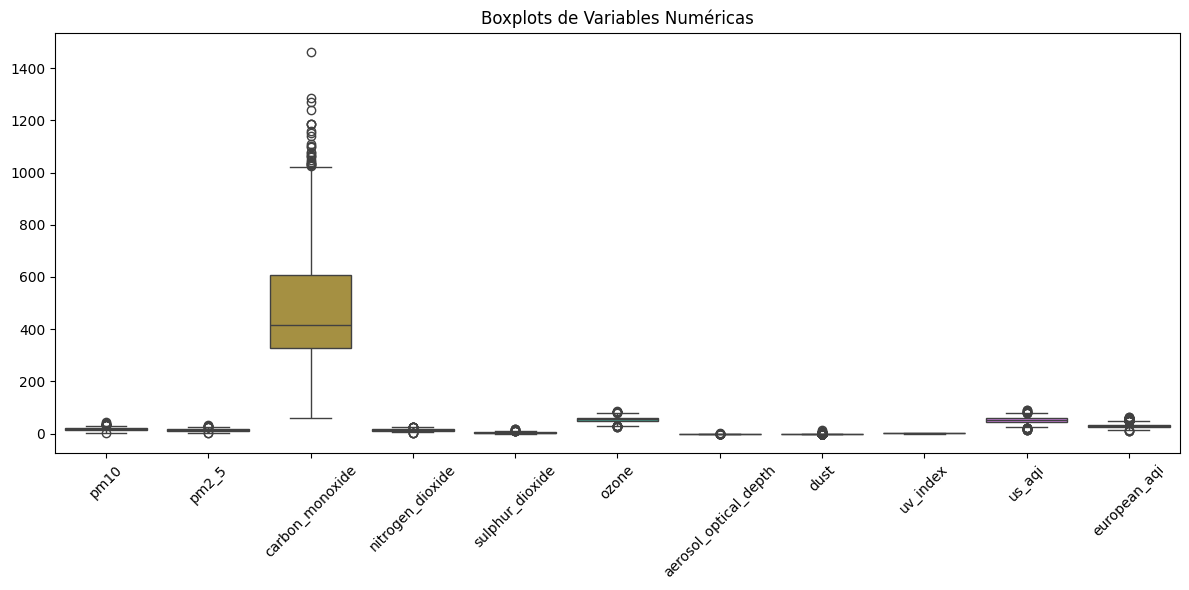

In [10]:
# Cálculo matemático de outliers con IQR (sobre el dataset depurado: 1.296 registros)
num_cols = df_cleaned.select_dtypes(include=np.number).columns
outliers_dict = {}

for col in num_cols:
    Q1 = df_cleaned[col].quantile(0.25)
    Q3 = df_cleaned[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_bajos = int((df_cleaned[col] < lower).sum())
    n_altos = int((df_cleaned[col] > upper).sum())
    outliers_dict[col] = {
        'Q1': Q1, 'Q3': Q3, 'Límite inferior': lower, 'Límite superior': upper,
        'Atípicos bajos': n_bajos, 'Atípicos altos': n_altos,
        'Total atípicos': n_bajos + n_altos,
        '% atípicos': round((n_bajos + n_altos) / len(df_cleaned) * 100, 2)
    }

tabla_iqr = pd.DataFrame(outliers_dict).T
tabla_iqr.index.name = 'Variable'
for c in ['Atípicos bajos', 'Atípicos altos', 'Total atípicos']:
    tabla_iqr[c] = tabla_iqr[c].astype(int)

print(f"--- CONTEO DE OUTLIERS POR EL CRITERIO IQR (n = {len(df_cleaned)}) ---")
display(tabla_iqr)

# Nota sobre dust: Q1 = Q3 = 0, por lo que cualquier día con polvo cuenta como "atípico"
pct_dust_cero = (df_cleaned['dust'] == 0).mean() * 100
print(f"\nNota: dust vale 0 en el {pct_dust_cero:.1f} % de los días (variable inflada en ceros). "
      f"Sus {tabla_iqr.loc['dust', 'Total atípicos']} 'atípicos' son todos los días con presencia de polvo, "
      f"no valores anómalos; por eso el criterio IQR no se aplica a esta variable.")

# Generación del Boxplot
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_cleaned[num_cols])
plt.xticks(rotation=45)
plt.title("Boxplots de Variables Numéricas")
plt.tight_layout()
plt.show()

In [11]:
top_pm25 = df_cleaned.nlargest(10, 'pm2_5')[['date', 'pm2_5', 'pm10', 'aerosol_optical_depth']]
top_pm25['mes'] = top_pm25['date'].dt.month
print('--- 10 DÍAS CON MAYOR PM2.5 DE LA SERIE ---')
display(top_pm25.reset_index(drop=True))

--- 10 DÍAS CON MAYOR PM2.5 DE LA SERIE ---


,date,pm2_5,pm10,aerosol_optical_depth,mes
0,2025-03-10,32.741667,33.087500,0.436667,3
1,2023-03-23,31.325000,44.804167,0.770417,3
2,2025-03-11,29.383333,29.666667,0.488750,3
3,2025-04-16,28.937500,30.595833,0.411667,4
4,2025-03-25,28.033333,29.845833,0.490000,3
5,2023-03-21,27.412500,39.312500,0.448333,3
6,2023-03-22,27.100000,38.812500,0.615833,3
7,2023-03-24,26.162500,37.475000,0.681250,3
8,2025-12-26,25.654167,26.025000,0.303750,12
9,2025-02-06,25.412500,26.745833,0.404167,2


los atípicos de PM2.5 y PM10 se concentran en febrero–abril (marzo de 2023 y marzo–abril de 2025), la temporada de transición climática en la que el Valle de Aburrá declara episodios críticos. Son eventos reales y es lo que el modelo debe aprender a anticipar, por lo que no se eliminan ni se recortan.

7. Distribución de las variables

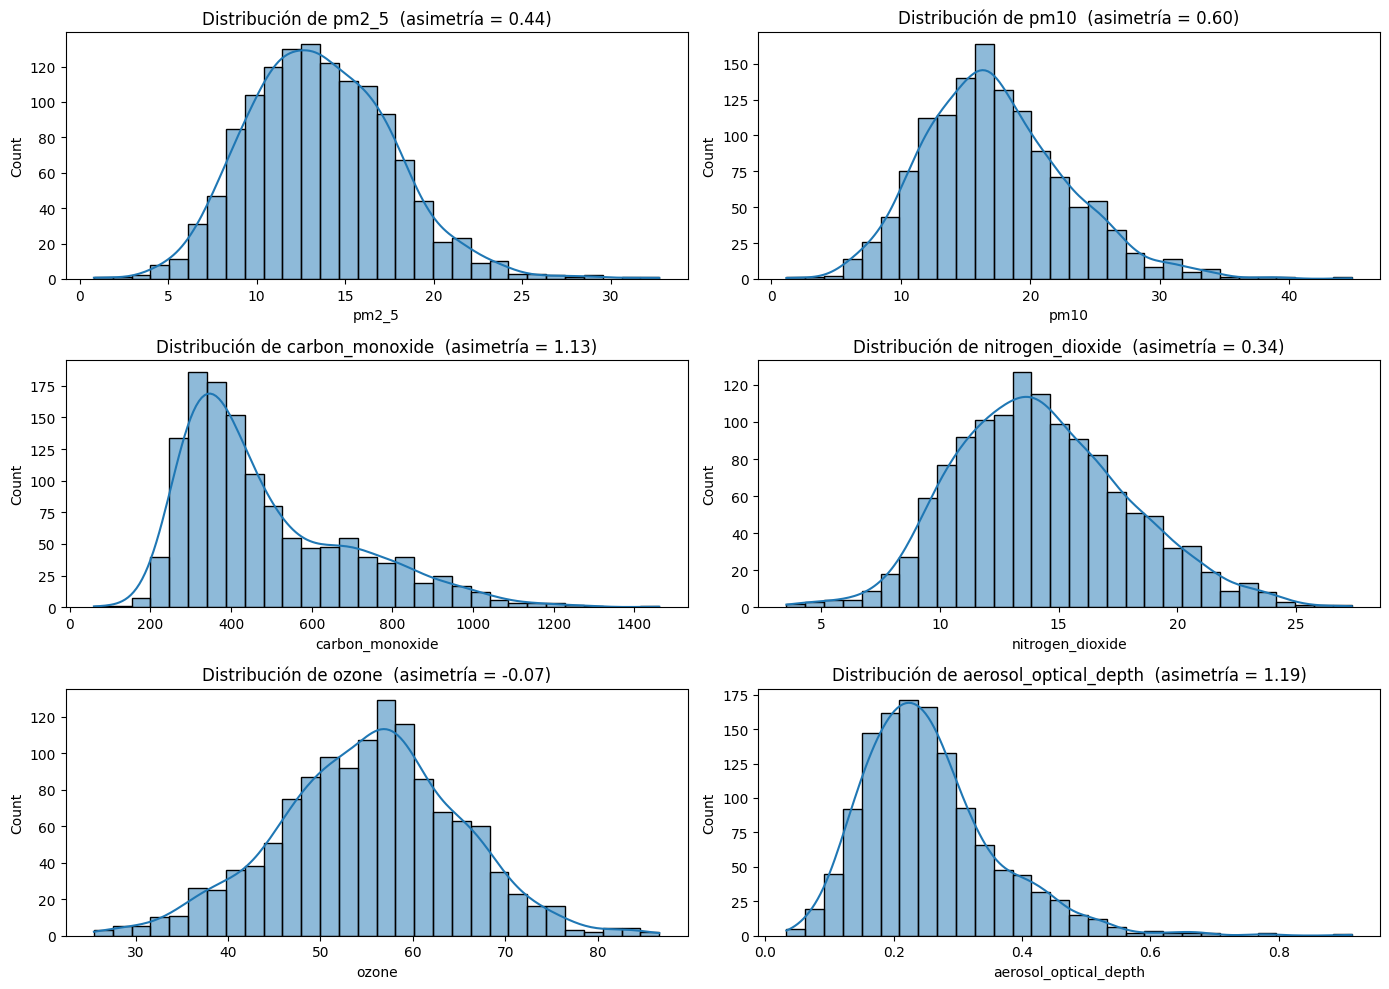

In [12]:
# Variables seleccionadas para visualizar su distribución
cols_dist = ['pm2_5', 'pm10', 'carbon_monoxide', 'nitrogen_dioxide', 'ozone', 'aerosol_optical_depth']
fig, axes = plt.subplots(3, 2, figsize=(14, 10))
for ax, col in zip(axes.flat, cols_dist):

    sns.histplot(df_cleaned[col], kde=True, bins=30, ax=ax)
    ax.set_title(f'Distribución de {col}  (asimetría = {df_cleaned[col].skew():.2f})')
plt.tight_layout()
plt.show()

8. Análisis de Correlación (Pearson)


--- MATRIZ DE CORRELACIÓN ---
                           pm10     pm2_5  carbon_monoxide  nitrogen_dioxide  sulphur_dioxide     ozone  aerosol_optical_depth      dust  uv_index    us_aqi  european_aqi
pm10                   1.000000  0.859984        -0.207584          0.232190        -0.074213  0.372407               0.623687  0.079316  0.093258  0.766478      0.713667
pm2_5                  0.859984  1.000000         0.184634          0.487134         0.157270  0.523917               0.607452  0.180602  0.028930  0.898440      0.887478
carbon_monoxide       -0.207584  0.184634         1.000000          0.418793         0.425842  0.265785               0.103046  0.166833 -0.139132  0.164075      0.248634
nitrogen_dioxide       0.232190  0.487134         0.418793          1.000000         0.460410  0.197946              -0.028052  0.208391  0.218798  0.404620      0.440357
sulphur_dioxide       -0.074213  0.157270         0.425842          0.460410         1.000000  0.255269           

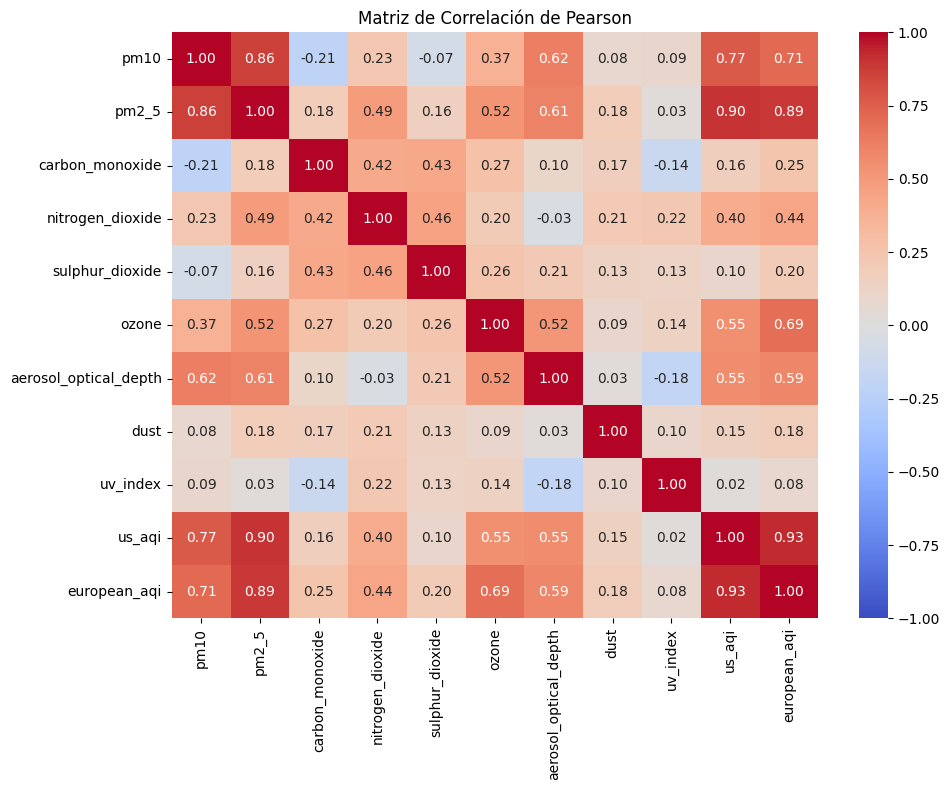

In [13]:
# Cálculo de la matriz de correlación
corr = df_cleaned[num_cols].corr()
print("\n--- MATRIZ DE CORRELACIÓN ---")
print(corr.to_string())

# Generación del Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title("Matriz de Correlación de Pearson")
plt.tight_layout()
plt.show()

9. Análisis Temporal

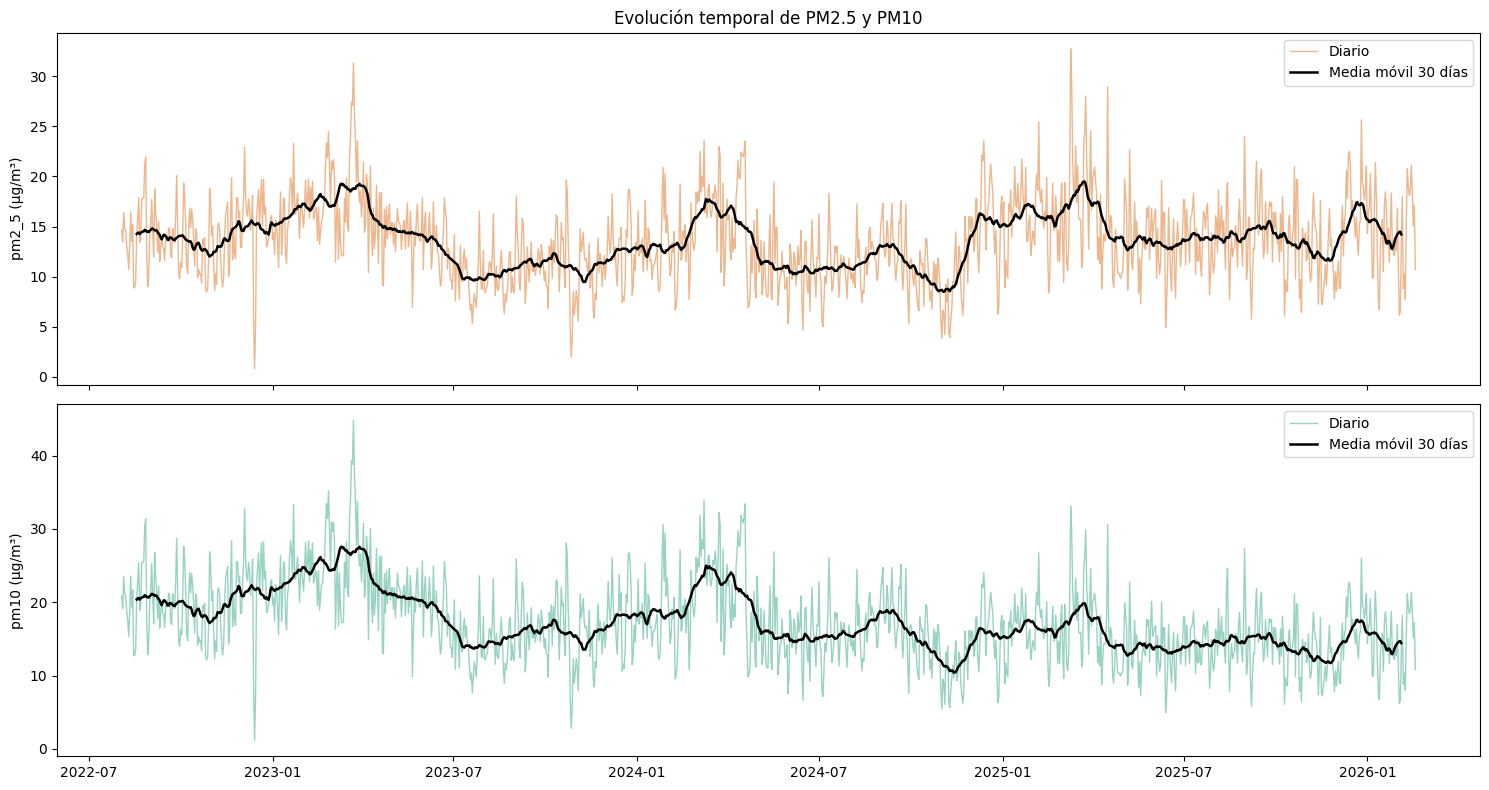

In [14]:
# 9.1 Series de las variables objetivo con media móvil de 30 días
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
for ax, col, color in zip(axes, OBJETIVOS, ['#d95f02', '#1b9e77']):
    ax.plot(df_cleaned['date'], df_cleaned[col], color=color, alpha=0.45, linewidth=1, label='Diario')
    ax.plot(df_cleaned['date'], df_cleaned[col].rolling(30, center=True).mean(), color='black',
            linewidth=1.8, label='Media móvil 30 días')
    ax.set_ylabel(f'{col} (µg/m³)')
    ax.legend(loc='upper right')
axes[0].set_title('Evolución temporal de PM2.5 y PM10')
plt.tight_layout()
plt.show()

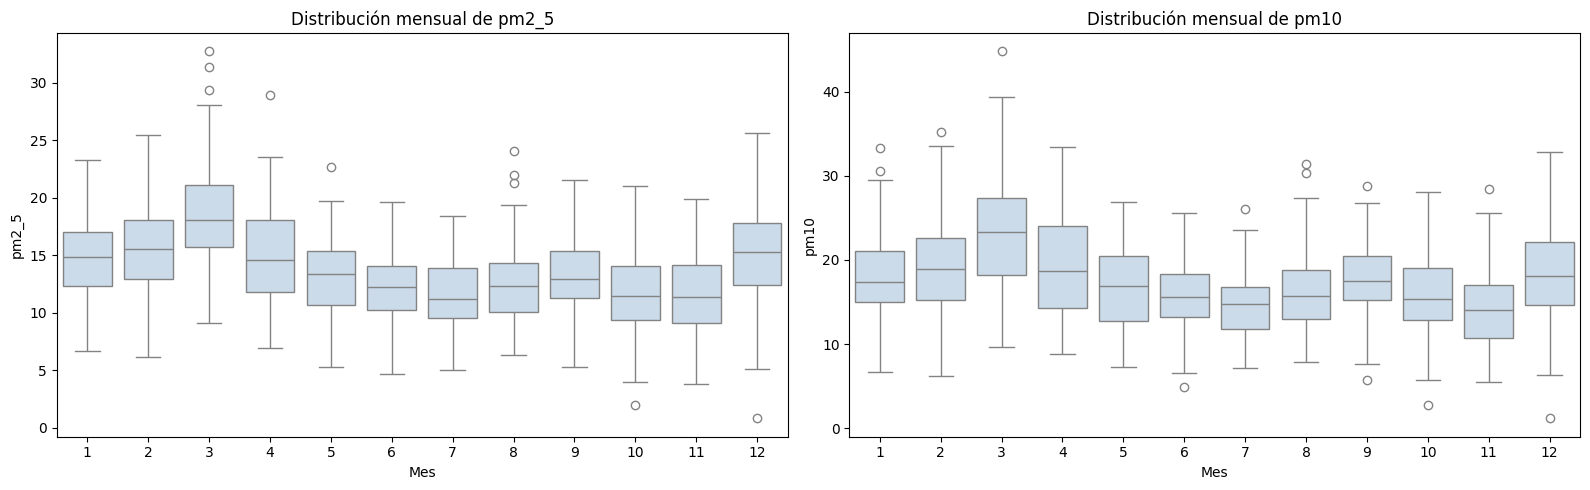

Mediana mensual (µg/m³):


mes,1,2,3,4,5,6,7,8,9,10,11,12
pm2_5,14.827083,15.558333,18.0375,14.610417,13.379167,12.262500,11.183333,12.331250,12.947917,11.479167,11.339583,15.300000
pm10,17.327083,18.933333,23.3625,18.643750,16.841667,15.545833,14.804167,15.760417,17.497917,15.316667,14.106250,18.095833


In [15]:
# 9.2 Estacionalidad mensual: ¿en qué meses ocurren los episodios críticos?
df_cleaned['mes'] = df_cleaned['date'].dt.month
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, col in zip(axes, OBJETIVOS):
    sns.boxplot(data=df_cleaned, x='mes', y=col, ax=ax, color='#c6dbef')
    ax.set_title(f'Distribución mensual de {col}')
    ax.set_xlabel('Mes')
plt.tight_layout()
plt.show()
print('Mediana mensual (µg/m³):')
display(df_cleaned.groupby('mes')[OBJETIVOS].median().T)
df_cleaned = df_cleaned.drop(columns='mes')

Media semestral de CO (µg/m³):
date
2022-08-01    313.0
2023-02-01    329.0
2023-08-01    377.0
2024-02-01    380.0
2024-08-01    534.0
2025-02-01    725.0
2025-08-01    713.0
2026-02-01    714.0
Freq: 6MS


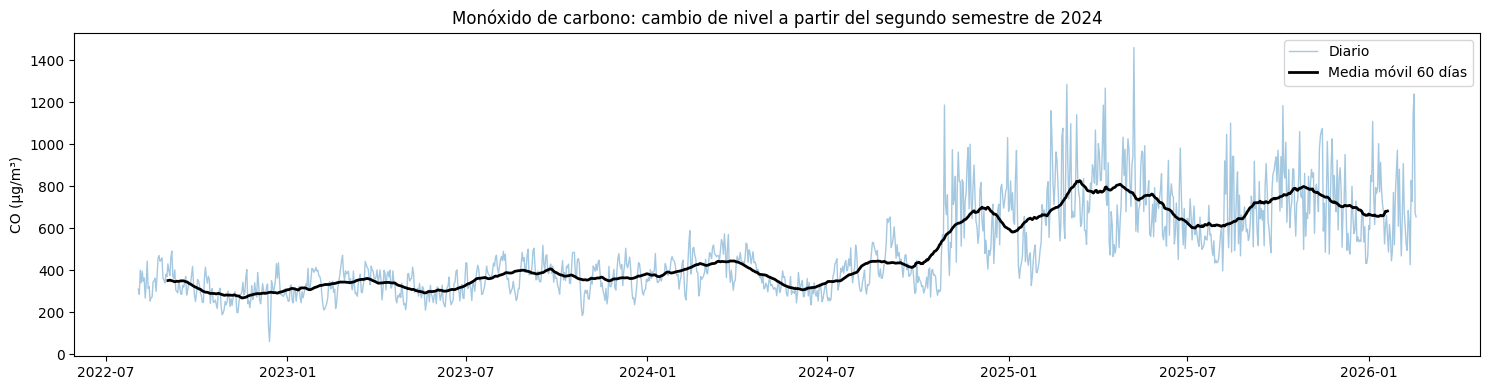

In [16]:
# 9.3 Cambio de nivel en el monóxido de carbono
co_semestral = df_cleaned.set_index('date')['carbon_monoxide'].resample('6MS').mean()
print('Media semestral de CO (µg/m³):')
print(co_semestral.round(0).to_string())

plt.figure(figsize=(15, 4))
plt.plot(df_cleaned['date'], df_cleaned['carbon_monoxide'], alpha=0.4, linewidth=1, label='Diario')
plt.plot(df_cleaned['date'], df_cleaned['carbon_monoxide'].rolling(60, center=True).mean(),
         color='black', linewidth=2, label='Media móvil 60 días')
plt.title('Monóxido de carbono: cambio de nivel a partir del segundo semestre de 2024')
plt.ylabel('CO (µg/m³)')
plt.legend()
plt.tight_layout()
plt.show()

10. Estacionariedad y autocorrelación

In [17]:
# 10.1 Prueba de Dickey-Fuller Aumentada (ADF)
filas_adf = []
for col in OBJETIVOS:
    estad, p, lags, nobs, crit, _ = adfuller(df_cleaned[col], autolag='AIC')
    filas_adf.append({'Variable': col, 'Estadístico ADF': estad, 'p-valor': p, 'Rezagos usados': lags,
                      'Valor crítico 1%': crit['1%'], 'Valor crítico 5%': crit['5%'],
                      'Estacionaria al 5%': p < 0.05, 'Estacionaria al 1%': p < 0.01})
print('--- PRUEBA ADF (H0: la serie tiene raíz unitaria / no es estacionaria) ---')
display(pd.DataFrame(filas_adf))

--- PRUEBA ADF (H0: la serie tiene raíz unitaria / no es estacionaria) ---


/tmp/ipykernel_4527/1101843651.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  estad, p, lags, nobs, crit, _ = adfuller(df_cleaned[col], autolag='AIC')
/tmp/ipykernel_4527/1101843651.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  estad, p, lags, nobs, crit, _ = adfuller(df_cleaned[col], autolag='AIC')


,Variable,Estadístico ADF,p-valor,Rezagos usados,Valor crítico 1%,Valor crítico 5%,Estacionaria al 5%,Estacionaria al 1%
0,pm2_5,-3.926390,0.001849,18,-3.435481,-2.863806,True,True
1,pm10,-3.321365,0.013950,18,-3.435481,-2.863806,True,False


In [18]:
# 10.2 Valores numéricos de ACF y PACF
N_LAGS = 10
banda = 1.96 / np.sqrt(len(df_cleaned))
tabla_acf = pd.DataFrame({'Rezago (días)': range(1, N_LAGS + 1)})
for col in OBJETIVOS:
    tabla_acf[f'ACF {col}'] = acf(df_cleaned[col], nlags=N_LAGS)[1:]
    tabla_acf[f'PACF {col}'] = pacf(df_cleaned[col], nlags=N_LAGS, method='ywm')[1:]
print(f'Banda de significancia al 95 %: ±{banda:.3f}')
display(tabla_acf.style.format(precision=3).map(
    lambda v: 'font-weight: bold; color: #b30000' if isinstance(v, float) and abs(v) > banda else '',
    subset=[c for c in tabla_acf.columns if 'PACF' in c]))

Banda de significancia al 95 %: ±0.054


,Rezago (días),ACF pm2_5,PACF pm2_5,ACF pm10,PACF pm10
0,1,0.643,0.643,0.691,0.691
1,2,0.403,-0.018,0.483,0.009
2,3,0.341,0.151,0.428,0.174
3,4,0.339,0.114,0.418,0.116
4,5,0.321,0.062,0.398,0.073
5,6,0.309,0.079,0.398,0.110
6,7,0.291,0.043,0.392,0.062
7,8,0.259,0.015,0.359,0.015
8,9,0.240,0.032,0.331,0.030
9,10,0.223,0.011,0.315,0.021


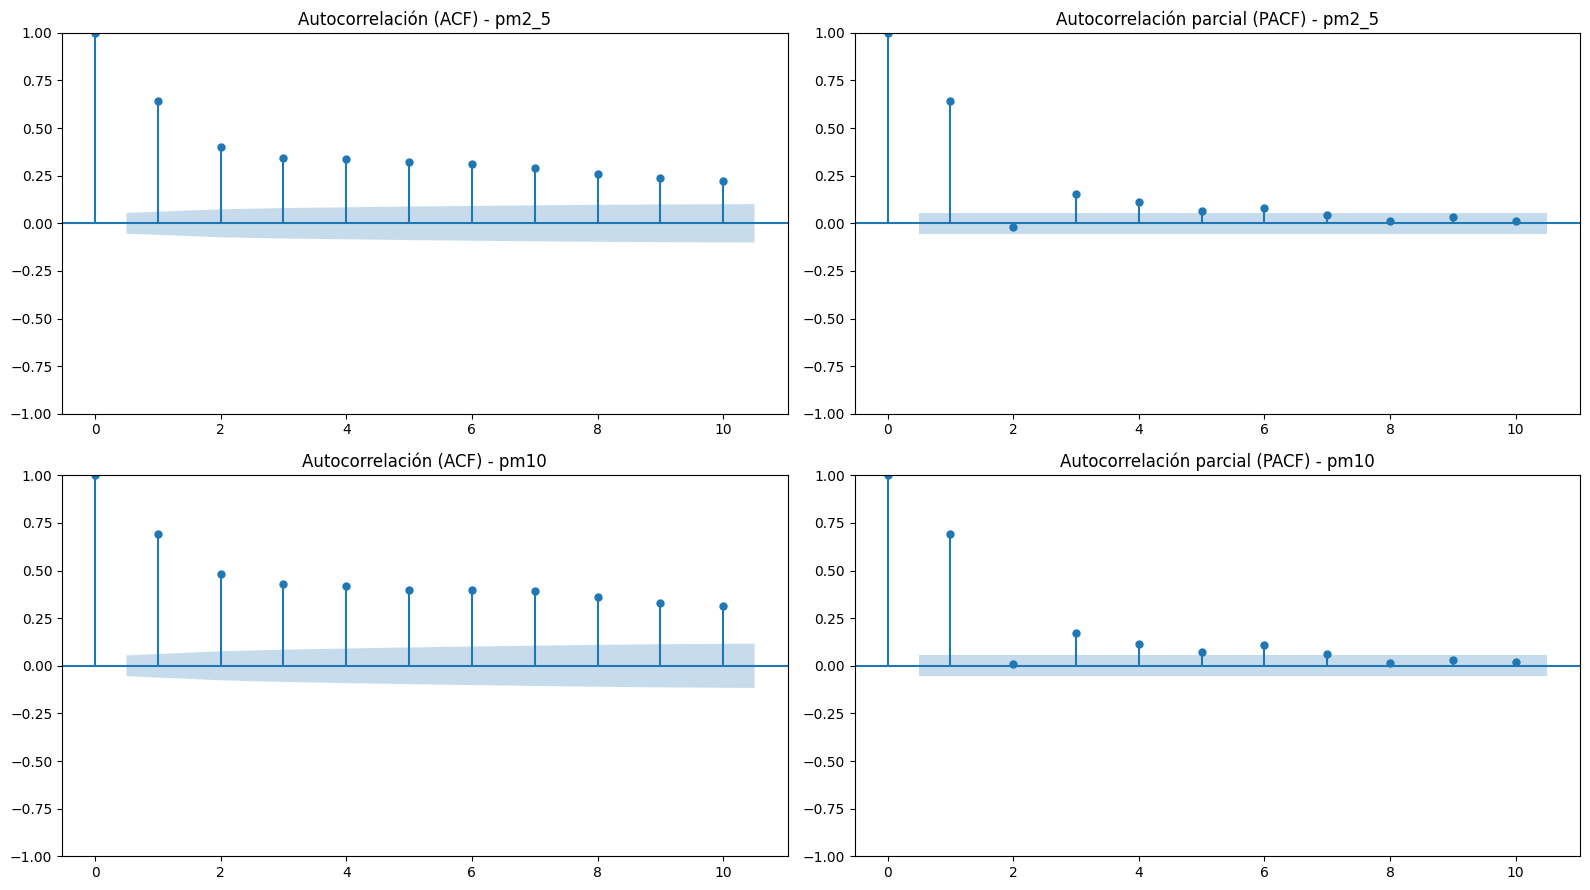

In [19]:
# 10.3 Correlogramas
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for i, col in enumerate(OBJETIVOS):
    plot_acf(df_cleaned[col], lags=N_LAGS, ax=axes[i, 0], title=f'Autocorrelación (ACF) - {col}')
    plot_pacf(df_cleaned[col], lags=N_LAGS, ax=axes[i, 1], method='ywm',
              title=f'Autocorrelación parcial (PACF) - {col}')
plt.tight_layout()
plt.show()

11. Revisión por periodos (año a año)

In [20]:
anual = df_cleaned.assign(año=df_cleaned['date'].dt.year).groupby('año')
yearly_stats = anual[['pm2_5', 'pm10', 'carbon_monoxide', 'us_aqi', 'european_aqi']].agg(['mean', 'max'])
yearly_stats.insert(0, ('días', 'n'), anual.size())
display(yearly_stats)
print('Nota: 2022 (desde el 3 de agosto) y 2026 (hasta el 18 de febrero) son años parciales; '
      'sus promedios no son comparables directamente con años completos.')

días      pm2_5                  pm10            carbon_monoxide  \
        n       mean        max       mean        max            mean   
año                                                                     
2022  151  14.060977  22.925000  20.106175  32.854167      312.477208   
2023  365  13.433139  31.325000  19.212477  44.804167      347.192922   
2024  366  12.551412  23.600000  17.020765  33.904167      444.362477   
2025  365  14.678447  32.741667  14.993779  33.087500      704.779224   
2026   49  14.318112  21.387500  14.478486  21.529167      712.518707   

                      us_aqi            european_aqi             
              max       mean        max         mean        max  
año                                                              
2022   490.791667  53.276104  75.041667    29.573951  54.208333  
2023   518.958333  51.163128  90.250000    30.004338  64.666667  
2024  1187.500000  48.670879  79.083333    29.021858  59.500000  
2025  1461.666667  54.712215  89.500000    33.490411  64.500000  
2026  1240.416667  53.773810  69.833333    33.335034  46.000000

Nota: 2022 (desde el 3 de agosto) y 2026 (hasta el 18 de febrero) son años parciales; sus promedios no son comparables directamente con años completos.


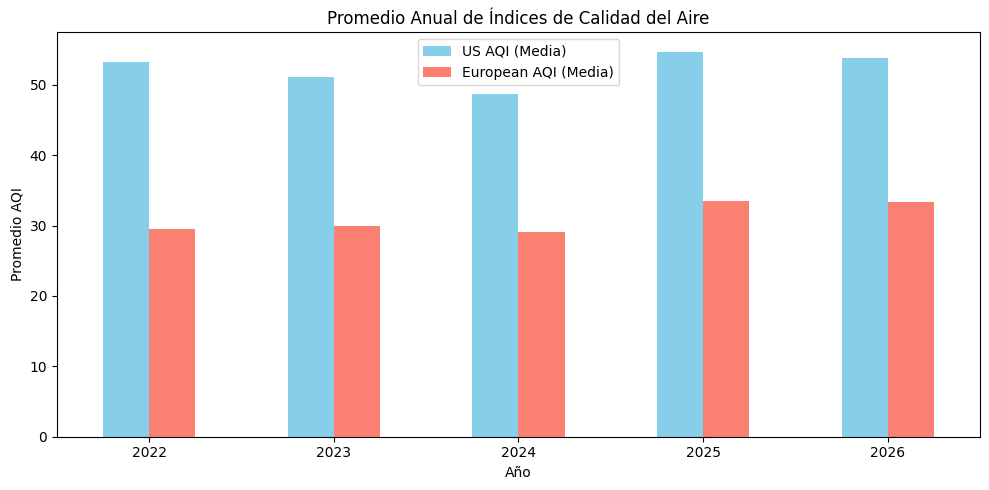

In [21]:
# Gráfico del promedio anual del AQI Estadounidense y Europeo
yearly_stats[[('us_aqi', 'mean'), ('european_aqi', 'mean')]].plot(kind='bar', figsize=(10, 5), color=['skyblue', 'salmon'])
plt.title("Promedio Anual de Índices de Calidad del Aire")
plt.xlabel("Año")
plt.ylabel("Promedio AQI")
plt.xticks(rotation=0)
plt.legend(['US AQI (Media)', 'European AQI (Media)'])
plt.tight_layout()
plt.show()

12. Integración de variables meteorológicas (Open-Meteo Historical Weather API)

In [22]:
import requests

LATITUD, LONGITUD = 6.2518, -75.5636      # <-- REEMPLAZAR por las coordenadas de la descarga original
ZONA_HORARIA = 'America/Bogota'
FECHA_INI = df_cleaned['date'].min().strftime('%Y-%m-%d')
FECHA_FIN = df_cleaned['date'].max().strftime('%Y-%m-%d')

VARIABLES_HORARIAS = ['temperature_2m', 'relative_humidity_2m', 'precipitation', 'wind_speed_10m',
                      'wind_direction_10m', 'shortwave_radiation', 'cloud_cover', 'surface_pressure']

def descargar_meteo(variables):
    r = requests.get('https://archive-api.open-meteo.com/v1/archive',
                     params={'latitude': LATITUD, 'longitude': LONGITUD, 'start_date': FECHA_INI,
                             'end_date': FECHA_FIN, 'hourly': ','.join(variables), 'timezone': ZONA_HORARIA},
                     timeout=120)
    r.raise_for_status()
    h = pd.DataFrame(r.json()['hourly'])
    h['time'] = pd.to_datetime(h['time'])
    return h

meteo_h = descargar_meteo(VARIABLES_HORARIAS)

# Altura de la capa límite (clave en el valle). Si el servicio no la ofrece, se continúa sin ella.
try:
    meteo_h = meteo_h.merge(descargar_meteo(['boundary_layer_height']), on='time', how='left')
    print('Altura de capa límite descargada.')
except Exception as e:
    print('Capa límite no disponible:', e)

print('Registros horarios:', meteo_h.shape)
display(meteo_h.head())

Altura de capa límite descargada.
Registros horarios: (31104, 10)


,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,wind_direction_10m,shortwave_radiation,cloud_cover,surface_pressure,boundary_layer_height
0,2022-08-03 00:00:00,17.2,100,0.0,1.3,214,0.0,100,855.2,30.0
1,2022-08-03 01:00:00,16.8,100,0.1,1.4,180,0.0,100,854.7,25.0
2,2022-08-03 02:00:00,16.6,100,0.1,3.1,126,0.0,100,853.8,35.0
3,2022-08-03 03:00:00,16.1,100,0.3,2.2,99,0.0,100,853.4,40.0
4,2022-08-03 04:00:00,15.9,100,0.0,2.7,113,0.0,100,853.3,35.0


12.1 Agregación diaria

In [23]:
meteo_h['date'] = meteo_h['time'].dt.floor('D')
# La dirección del viento es circular: se promedia por componentes u (oeste-este) y v (sur-norte)
rad = np.deg2rad(meteo_h['wind_direction_10m'])
meteo_h['viento_u'] = -meteo_h['wind_speed_10m'] * np.sin(rad)
meteo_h['viento_v'] = -meteo_h['wind_speed_10m'] * np.cos(rad)

agregaciones = {
    'temp_media': ('temperature_2m', 'mean'), 'temp_max': ('temperature_2m', 'max'),
    'temp_min': ('temperature_2m', 'min'), 'humedad_media': ('relative_humidity_2m', 'mean'),
    'precipitacion_sum': ('precipitation', 'sum'), 'viento_vel_media': ('wind_speed_10m', 'mean'),
    'viento_vel_max': ('wind_speed_10m', 'max'), 'viento_u_media': ('viento_u', 'mean'),
    'viento_v_media': ('viento_v', 'mean'), 'radiacion_sum': ('shortwave_radiation', 'sum'),
    'nubosidad_media': ('cloud_cover', 'mean'), 'presion_media': ('surface_pressure', 'mean'),
}
if 'boundary_layer_height' in meteo_h.columns and meteo_h['boundary_layer_height'].notna().any():
    agregaciones['capa_limite_media'] = ('boundary_layer_height', 'mean')
    agregaciones['capa_limite_min'] = ('boundary_layer_height', 'min')

meteo_d = meteo_h.groupby('date').agg(**agregaciones).reset_index()
meteo_d['amplitud_termica'] = meteo_d['temp_max'] - meteo_d['temp_min']   # baja amplitud ~ estabilidad atmosférica
COLS_METEO = [c for c in meteo_d.columns if c != 'date']
print('Variables meteorológicas diarias:', COLS_METEO)
display(meteo_d.describe().T)

Variables meteorológicas diarias: ['temp_media', 'temp_max', 'temp_min', 'humedad_media', 'precipitacion_sum', 'viento_vel_media', 'viento_vel_max', 'viento_u_media', 'viento_v_media', 'radiacion_sum', 'nubosidad_media', 'presion_media', 'capa_limite_media', 'capa_limite_min', 'amplitud_termica']


,count,mean,min,25%,50%,75%,max,std
date,1296,2024-05-11 12:00:00,2022-08-03 00:00:00,2023-06-22 18:00:00,2024-05-11 12:00:00,2025-03-31 06:00:00,2026-02-18 00:00:00,NaN
temp_media,1296.0,20.363458,17.5125,19.6375,20.352083,21.070833,23.6625,1.023291
temp_max,1296.0,26.528241,20.9,25.3,26.6,27.7,31.8,1.744318
temp_min,1296.0,16.286497,12.8,15.7,16.4,17.0,19.2,0.911519
humedad_media,1296.0,84.370113,62.25,80.03125,85.5,88.84375,96.375,5.672097
precipitacion_sum,1296.0,5.975309,0.0,0.8,3.7,9.9,58.4,6.230508
viento_vel_media,1296.0,4.101244,1.675,2.954167,3.833333,5.208333,7.65,1.405973
viento_vel_max,1296.0,8.72662,3.4,6.4,8.0,10.6,17.8,3.059698
viento_u_media,1296.0,-2.755978,-7.412333,-4.709861,-2.759159,-1.031982,6.72142,2.393405
viento_v_media,1296.0,-0.075115,-2.090574,-0.50428,-0.125121,0.298999,2.149976,0.624939


12.2 Unión, verificación y correlación con PM

Dimensiones: (1296, 27) | Nulos meteorológicos: 362
--- CORRELACIÓN DE LA METEOROLOGÍA CON EL MATERIAL PARTICULADO ---


,Pearson PM2.5,Pearson PM10
viento_v_media,-0.200,-0.188
viento_u_media,-0.167,-0.196
precipitacion_sum,-0.142,-0.140
humedad_media,-0.097,-0.019
presion_media,-0.094,-0.094
temp_min,-0.030,-0.142
viento_vel_max,-0.028,-0.007
nubosidad_media,-0.027,-0.040
viento_vel_media,-0.015,0.084
capa_limite_min,-0.005,-0.092


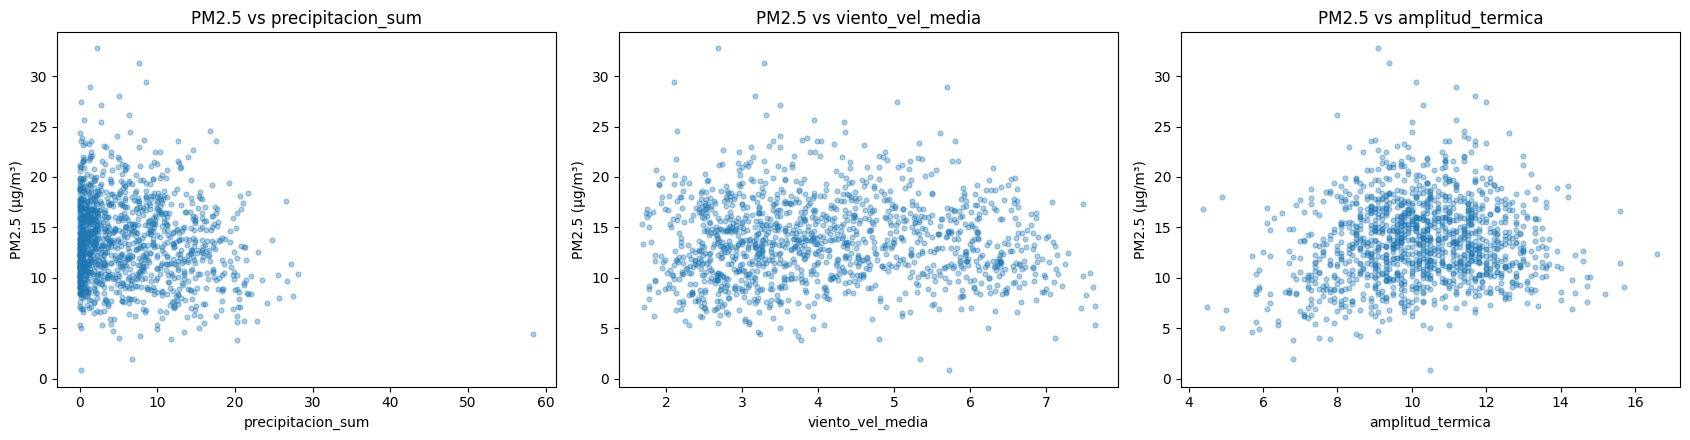

In [24]:
df_meteo = df_cleaned.merge(meteo_d, on='date', how='left')
print('Dimensiones:', df_meteo.shape, '| Nulos meteorológicos:', int(df_meteo[COLS_METEO].isnull().sum().sum()))
df_meteo[COLS_METEO] = df_meteo[COLS_METEO].interpolate(method='linear').bfill().ffill()

corr_meteo = pd.DataFrame({
    'Pearson PM2.5': df_meteo[COLS_METEO].corrwith(df_meteo['pm2_5']),
    'Pearson PM10': df_meteo[COLS_METEO].corrwith(df_meteo['pm10']),
}).sort_values('Pearson PM2.5')
print('--- CORRELACIÓN DE LA METEOROLOGÍA CON EL MATERIAL PARTICULADO ---')
display(corr_meteo.round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, ['precipitacion_sum', 'viento_vel_media', 'amplitud_termica']):
    ax.scatter(df_meteo[col], df_meteo['pm2_5'], alpha=0.35, s=12)
    ax.set_xlabel(col); ax.set_ylabel('PM2.5 (µg/m³)'); ax.set_title(f'PM2.5 vs {col}')
plt.tight_layout(); plt.show()

12.3 Guargar el archivo para el capitulo 2

In [25]:
meteo_d.to_csv('/content/drive/MyDrive/meteorologia_diaria.csv', index=False)
print('Guardado en Drive: meteorologia_diaria.csv', meteo_d.shape)

Guardado en Drive: meteorologia_diaria.csv (1296, 16)
